Epoch 1/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.4191 - loss: 1.9510 - val_accuracy: 0.9443 - val_loss: 0.2250
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9589 - loss: 0.1545 - val_accuracy: 0.9956 - val_loss: 0.0284
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9973 - loss: 0.0232 - val_accuracy: 0.9996 - val_loss: 0.0087
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9987 - loss: 0.0101 - val_accuracy: 0.9971 - val_loss: 0.0180
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9998 - loss: 0.0050 - val_accuracy: 0.9993 - val_loss: 0.0028
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9988 - loss: 0.0047 - val_accuracy: 0.9938 - val_loss: 0.0201
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9952 - loss: 0.0157 - val_accuracy: 1.0000 - val_loss: 5.8610e-04
Epoch 8/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 1.0000 - loss: 4.630

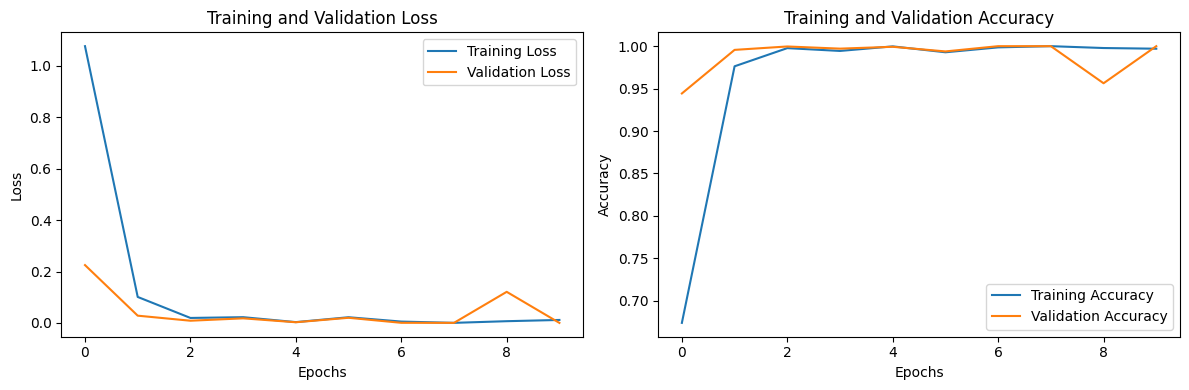

In [1]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Input, Flatten, Dense

train_data = pd.read_csv("Datasets/FNN_CNN/S_MNIST/sign_mnist_train.csv")
test_data = pd.read_csv("Datasets/FNN_CNN/S_MNIST/sign_mnist_test.csv")

x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

y_train = y_train.copy()
y_test = y_test.copy()

y_train[y_train > 9] -= 1
y_test[y_test > 9] -= 1

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(24, activation='softmax')
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()